# Propagation Analysis

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import ShortTimeFFT, welch
from scipy.signal.windows import hann
from tqdm import tqdm
from tritonoa.modeling.at.kraken import run_kraken
from tritonoa.modeling.physics import propagate_signal
from tritonoa.signal import waveforms
from tritonoa.signal.util import get_freqs_from_band

plt.style.use(Path("config/jasa_fig_style.mplstyle"))

SAVEPATH = Path.cwd() / "results"

In [3]:
def construct_environment() -> dict:
    z = np.array([0, 35])
    return {
        # 1. General
        "title": "Munk",
        "model": "KRAKEN",
        # 2. Top medium (halfspace)
        "top_opt": "CVW    ",
        # 3. Layered media
        "layerdata": [
            {"z": z, "c_p": 1500.0, "rho": 1.0},
            {"z": [z.max(), 200], "c_p": 1600.0, "rho": 1.5, "a_p": 0.2},
        ],
        # 4. Bottom medium
        "bot_opt": "A",
        "bot_c_p": 1600.0,
        "bot_rho": 1.5,
        "bot_a_p": 0.2,
        # 5. Speed constraints
        "clow": 0,
        "chigh": 1600,
        # 6. Receiver parameters
        "rec_z": 20.0,
        "rec_r": 2.0,
        # 7. Source parameters
        "src_z": 25.0,
    }

## Mode Function

In [4]:
def plot_mode_function(
    environment: dict, phis: list[np.ndarray], freqs: list[float], zgrid: np.ndarray
) -> plt.Figure:
    fig, axs = plt.subplots(ncols=3, gridspec_kw={"wspace": 0.05}, figsize=(6, 4))
    for i, (ax, phi, freq) in enumerate(zip(axs, phis, freqs)):
        ax.plot(np.real(phi), zgrid, c="tab:blue", lw=1, label="$\\Phi_m$")
        ax.plot(np.real(phi).sum(axis=1), zgrid, c="k", lw=2, label="$\\Sigma\\Phi_m$")
        ax.axhline(environment["layerdata"][0]["z"].max(), color="k", linestyle="--")
        ax.axvline(0.0, color="k")
        ax.set_xlim(-0.6, 0.6)
        ax.set_ylim(-0.1, zgrid.max() + 0.1)
        ax.invert_yaxis()
        if i == 0:
            ax.set_xlabel("Amplitude")
            ax.set_ylabel("Depth (m)")
        if i != 0:
            ax.set_yticklabels([])

        num_modes = phi.shape[1]
        modes_display = f"{num_modes} modes" if num_modes > 1 else "1 mode"
        ax.set_title(f"$f$ = {freq:.0f} Hz\n{modes_display}")

    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.02),
        bbox_transform=fig.transFigure,
    )
    return fig

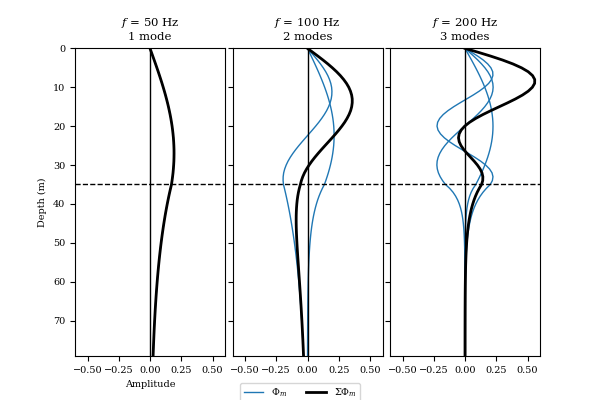

In [5]:
freqs = [50.0, 100.0, 200.0]
zgrid = np.arange(0, 80, 1)
environment = construct_environment() | {"rec_z": zgrid}

phis = []
for freq in freqs:
    model = run_kraken(environment | {"freq": freq, "rec_z": zgrid})
    phis.append(model.modes.phi_rec)

fig = plot_mode_function(environment, phis, freqs, zgrid)
fig.savefig(SAVEPATH / "mode_function.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

## Pulse Propagation

In [15]:
def plot_orig_and_dispersed(t, x, y):
    fig, axs = plt.subplots(nrows=2)
    ax = axs[0]
    ax.plot(t, x)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure (Pa)")
    ax = axs[1]
    ax.plot(t, y)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Reduced time (s)")
    ax.set_ylabel("Pressure (Pa)")
    fig.tight_layout()
    return fig

100%|██████████| 959/959 [00:19<00:00, 48.82it/s]


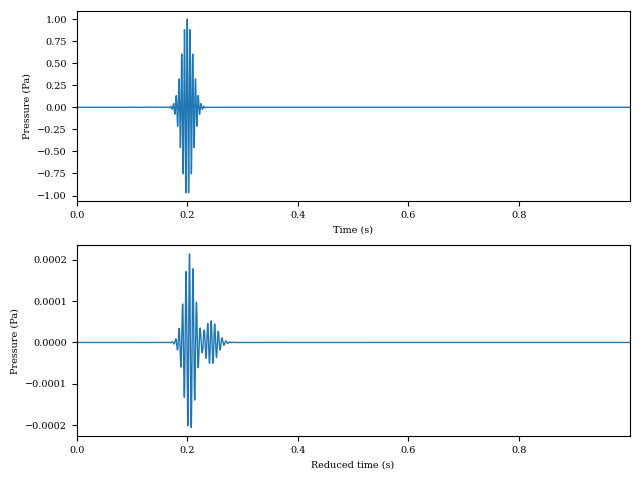

In [51]:
factor = 2.0
fc = 100.0 * factor
# bw = 195.0
T = 40 / fc * factor
fs = 8192.0 * 2
pulse = waveforms.generate_gaussian_pulse(T, fc, fs, sigma=0.01)
# pulse = waveforms.generate_cw(T, fc, fs)

dt = 1 / fs
t = np.arange(0, T - dt, dt)


# factor = 1.0
# fc = 100.0 * factor
# bw = 100.0
# pulse_dur = 4 / fc * factor
fl = 40
fu = 1000
# fs = 8192.0
# pulse = waveforms.generate_cw(pulse_dur, fc, fs)
window = hann(len(pulse))
pulse *= window
T = 1.0
t = np.arange(0, T, 1 / fs)
N = t.size
x = np.concatenate([pulse, np.zeros(N - pulse.size)])
x += np.random.normal(0, 1e-8, N)

# Define frequencies
freqs, inds = get_freqs_from_band(len(x), [fl, fu], fs=fs)

# Define the environment
environment = construct_environment()

# Expected travel time:
c_max = 1500.0
t_offset = environment["rec_r"] * 1e3 / c_max

# Compute Green's Function
p = np.zeros((len(freqs),), dtype=complex)
for i, freq in tqdm(enumerate(freqs), total=len(freqs)):
    model = run_kraken(environment | {"freq": freq})
    p[i] = model.modes.p.squeeze()

# Propagate signal
y = propagate_signal(x, p, freqs, inds, t_offset, nfft=N)

fig = plot_orig_and_dispersed(t, x, y)
plt.show()



In [52]:
M = 512
pcoverlap = 0.9
win = hann(M)
SFT = ShortTimeFFT(win, hop=int((1 - pcoverlap) * M), mfft=8*M, fs=fs, scale_to="psd")
Sx = SFT.stft(x)
Sy = SFT.stft(y)
Sx = 10 * np.log10(np.abs(Sx) ** 2)
Sy = 10 * np.log10(np.abs(Sy) ** 2)

t = SFT.t(len(x))

/var/folders/nj/vwkt9bx54ts200_1q_7bh0140000gn/T/ipykernel_82302/3514217635.py:7: RuntimeWarning: divide by zero encountered in log10
  Sx = 10 * np.log10(np.abs(Sx) ** 2)
/var/folders/nj/vwkt9bx54ts200_1q_7bh0140000gn/T/ipykernel_82302/3514217635.py:8: RuntimeWarning: divide by zero encountered in log10
  Sy = 10 * np.log10(np.abs(Sy) ** 2)


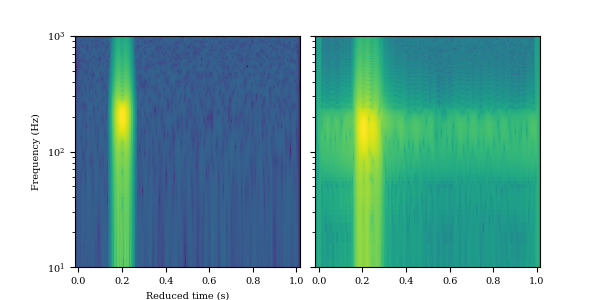

In [53]:
ylim = (10, 1000)

fig, axs = plt.subplots(ncols=2, figsize=(6, 3), gridspec_kw={"wspace": 0.07})
ax = axs[0]
# im = ax.imshow(Sx, aspect="auto", origin="lower", extent=SFT.extent(len(x)), interpolation="none")
im = ax.pcolormesh(t, SFT.f, Sx[0:-1, 0:-1], shading="flat")
ax.set_yscale("log")
ax.set_ylim(ylim)
ax.set_xlabel("Reduced time (s)")
ax.set_ylabel("Frequency (Hz)")

ax = axs[1]
im = ax.pcolormesh(t, SFT.f, Sy[0:-1, 0:-1], shading="flat")
ax.set_yscale("log")
ax.set_ylim(ylim)
ax.set_yticklabels([])

plt.show()

# TODO: Figure out how to adjust extent more easily

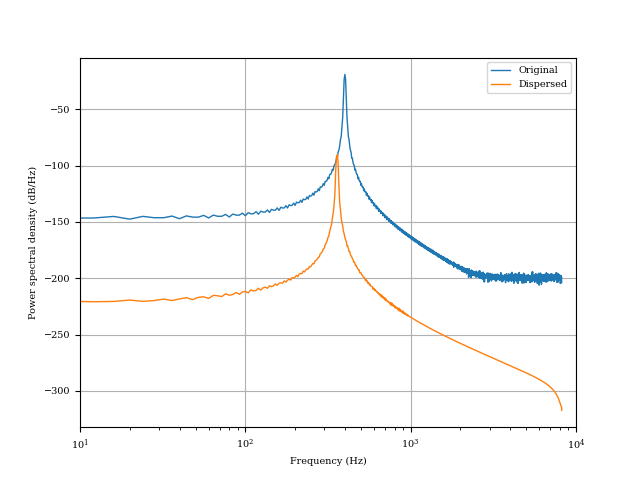

In [10]:
f, Pxx = welch(x, fs=fs, nperseg=4096, noverlap=2048)
_, Pyy = welch(y, fs=fs, nperseg=4096, noverlap=2048)

Pxx = 10 * np.log10(Pxx)
Pyy = 10 * np.log10(Pyy)

fig = plt.figure()
plt.plot(f, Pxx, c="tab:blue", label="Original")
plt.plot(f, Pyy, c="tab:orange", label="Dispersed")
plt.xscale("log")
plt.grid(True)
plt.xlim(10, 10000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density (dB/Hz)")
plt.legend()
plt.show()